# HitPredict: Predicting Billboard Hits Using Spotify Data
**UE24CS352A Machine Learning Mini-Project** · Team A-06 · Ahan A Mysore (PES1UG24AM019), Bhoomika Patil (PES1UG25AM801)

Inspired by *HitPredict* (Georgieva, Suta, Burton; Stanford CS229, 2018). Task: binary classification, **1 = Billboard Hot 100 song, 0 = non-hit**, from Spotify audio features.

**What changed in this version (v2).** The original notebook reported ~89% accuracy, but the data is 89% hits, so *always predicting "hit"* scores the same 89.2%. The models found almost no non-hits (recall 0.6-1.8%). This version fixes the evaluation: duplicates removed, class weighting, stratified 5-fold CV, metrics that respect imbalance (balanced accuracy, macro-F1, non-hit recall, ROC-AUC), a majority-class baseline, and a `Popularity` ablation.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid"); RS = 42
os.makedirs("figures", exist_ok=True)

## 1. Build / load the dataset
If `HitPredict_Final_Dataset.csv` exists it is loaded. Otherwise it is rebuilt from the two raw Kaggle files (`Billboard_Hot100_Songs_Spotify_1946-2022.csv`, `playlist_2010to2023.csv`) with the same logic as v1.

In [2]:
FEATS = ["Popularity","Acousticness","Danceability","Energy","Instrumentalness","Liveness",
         "Loudness","Speechiness","Tempo","Valence","Key","Mode","Time Signature","Song Length(ms)"]

def clean_song_name(x):
    x = str(x).lower().strip()
    for a, b in [("'", ""), ('"', ""), ("-", " "), ("(", ""), (")", "")]:
        x = x.replace(a, b)
    return " ".join(x.split())

def build_dataset():
    bb = pd.read_csv("Billboard_Hot100_Songs_Spotify_1946-2022.csv")
    pl = pd.read_csv("playlist_2010to2023.csv", encoding="latin1")
    bb["song_clean"] = bb["Song"].apply(clean_song_name)
    pl["song_clean"] = pl["track_name"].apply(clean_song_name)
    non = pl[~pl["song_clean"].isin(set(bb["song_clean"]))]
    non = non[non["year"] <= 2022].copy()
    bb_ml = bb[FEATS].assign(hit=1)
    pl_ml = non[["track_popularity","acousticness","danceability","energy","instrumentalness","liveness",
                 "loudness","speechiness","tempo","valence","key","mode","time_signature","duration_ms"]].copy()
    pl_ml.columns = FEATS; pl_ml["hit"] = 0
    return pd.concat([bb_ml, pl_ml], ignore_index=True).dropna().reset_index(drop=True)

if os.path.exists("HitPredict_Final_Dataset.csv"):
    raw = pd.read_csv("HitPredict_Final_Dataset.csv")
else:
    raw = build_dataset(); raw.to_csv("HitPredict_Final_Dataset.csv", index=False)
print("Loaded:", raw.shape)
print(raw.hit.value_counts().rename({1:"hit",0:"non-hit"}))

Loaded: (7713, 15)
hit
hit        6879
non-hit     834
Name: count, dtype: int64


## 2. Data audit (the problems v1 missed)

Exact duplicate rows: 358  (hits: 341, non-hits: 17)
-> songs that charted in several years appear several times; copies land in both train and test (leakage).
After de-duplication: (7355, 15) | hit share = 0.889

Mean feature value by class:


,Popularity,Loudness,Energy,Acousticness,Danceability,Song Length(ms)
hit,,,,,,
0,68.52,-5.86,0.7,0.17,0.65,218862.72
1,53.51,-8.81,0.6,0.30,0.62,224516.60


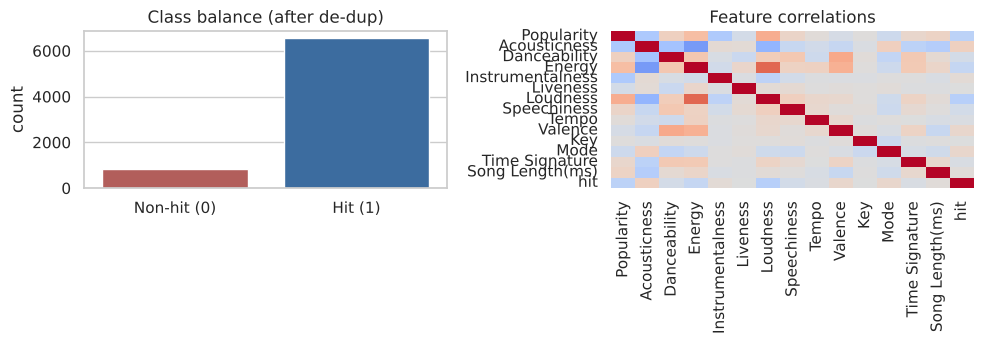

In [3]:
n_dup = raw.duplicated().sum()
print(f"Exact duplicate rows: {n_dup}  (hits: {raw[raw.duplicated()].hit.sum()}, non-hits: {(raw[raw.duplicated()].hit==0).sum()})")
print("-> songs that charted in several years appear several times; copies land in both train and test (leakage).")
df = raw.drop_duplicates().reset_index(drop=True)
print("After de-duplication:", df.shape, "| hit share = %.3f" % df.hit.mean())
print("\nMean feature value by class:")
display(df.groupby("hit")[["Popularity","Loudness","Energy","Acousticness","Danceability","Song Length(ms)"]].mean().round(2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
sns.countplot(x="hit", data=df, ax=ax[0], palette=["#c0504d", "#2b6cb0"]); ax[0].set_title("Class balance (after de-dup)")
ax[0].set_xticklabels(["Non-hit (0)", "Hit (1)"]); ax[0].set_xlabel("")
sns.heatmap(df.corr(), cmap="coolwarm", center=0, ax=ax[1], cbar=False); ax[1].set_title("Feature correlations")
plt.tight_layout(); plt.savefig("figures/data_audit.png", dpi=160); plt.show()

## 3. Why v1's 89% was misleading
Reproduce v1 exactly (same split, same models, no class weighting) next to a majority-class baseline.

In [4]:
X = raw.drop(columns="hit"); y = raw.hit
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=RS, stratify=y)

def report(name, m, Xtr, Xte, ytr, yte):
    m.fit(Xtr, ytr); p = m.predict(Xte)
    s = m.predict_proba(Xte)[:,1] if hasattr(m,"predict_proba") else np.zeros(len(yte))
    return dict(Model=name, Accuracy=accuracy_score(yte,p), BalancedAcc=balanced_accuracy_score(yte,p),
        NonHitRecall=recall_score(yte,p,pos_label=0), MacroF1=f1_score(yte,p,average="macro"),
        AUC=roc_auc_score(yte,s) if s.any() else 0.5)

v1 = [report("Majority baseline", DummyClassifier(strategy="most_frequent"), Xtr,Xte,ytr,yte),
      report("v1 Logistic Reg.", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RS)), Xtr,Xte,ytr,yte),
      report("v1 Decision Tree", DecisionTreeClassifier(max_depth=5, random_state=RS), Xtr,Xte,ytr,yte),
      report("v1 Random Forest", RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RS), Xtr,Xte,ytr,yte)]
v1 = pd.DataFrame(v1).set_index("Model").round(3); display(v1)
print("Accuracy equals the baseline while non-hit recall is ~0: the models just predict 'hit' for almost everything.")

,Accuracy,BalancedAcc,NonHitRecall,MacroF1,AUC
Model,,,,,
Majority baseline,0.892,0.500,0.000,0.471,0.500
v1 Logistic Reg.,0.890,0.505,0.012,0.483,0.812
v1 Decision Tree,0.889,0.506,0.018,0.487,0.824
v1 Random Forest,0.892,0.503,0.006,0.477,0.868


Accuracy equals the baseline while non-hit recall is ~0: the models just predict 'hit' for almost everything.


## 4. Corrected evaluation
De-duplicated data, `class_weight='balanced'`, stratified 5-fold cross-validation (mean ± std over folds).

In [5]:
Xd = df.drop(columns="hit"); yd = df.hit
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
SCORING = {"accuracy":"accuracy","balanced_acc":"balanced_accuracy","macro_f1":"f1_macro","auc":"roc_auc",
           "nonhit_recall":"recall_macro"}  # placeholder replaced below
from sklearn.metrics import make_scorer
SCORING["nonhit_recall"] = make_scorer(recall_score, pos_label=0)
SCORING["nonhit_precision"] = make_scorer(precision_score, pos_label=0, zero_division=0)

def models():
    return {"Majority baseline": DummyClassifier(strategy="most_frequent"),
      "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RS)),
      "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RS),
      "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=RS, n_jobs=-1)}

def run_cv(drop=()):
    rows = []
    for n, m in models().items():
        r = cross_validate(m, Xd.drop(columns=list(drop)), yd, cv=cv, scoring=SCORING)
        rows.append({"Model": n, **{k[5:]: f"{v.mean():.3f} ± {v.std():.3f}" for k, v in r.items() if k.startswith("test_")},
                     **{"_"+k[5:]: v.mean() for k, v in r.items() if k.startswith("test_")}})
    return pd.DataFrame(rows).set_index("Model")

res_all = run_cv(); res_nopop = run_cv(["Popularity"])
show = ["accuracy","balanced_acc","macro_f1","auc","nonhit_recall","nonhit_precision"]
print("A) All 14 features"); display(res_all[show])
print("B) Without Popularity (pure audio features)"); display(res_nopop[show])

A) All 14 features


,accuracy,balanced_acc,macro_f1,auc,nonhit_recall,nonhit_precision
Model,,,,,,
Majority baseline,0.889 ± 0.000,0.500 ± 0.000,0.471 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Logistic Regression,0.702 ± 0.013,0.754 ± 0.007,0.592 ± 0.009,0.806 ± 0.015,0.820 ± 0.022,0.247 ± 0.007
Decision Tree,0.682 ± 0.041,0.746 ± 0.010,0.577 ± 0.026,0.789 ± 0.014,0.829 ± 0.054,0.237 ± 0.016
Random Forest,0.753 ± 0.013,0.739 ± 0.015,0.619 ± 0.011,0.828 ± 0.010,0.721 ± 0.035,0.271 ± 0.011


B) Without Popularity (pure audio features)


,accuracy,balanced_acc,macro_f1,auc,nonhit_recall,nonhit_precision
Model,,,,,,
Majority baseline,0.889 ± 0.000,0.500 ± 0.000,0.471 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Logistic Regression,0.681 ± 0.015,0.721 ± 0.014,0.569 ± 0.012,0.785 ± 0.010,0.772 ± 0.024,0.226 ± 0.010
Decision Tree,0.668 ± 0.024,0.723 ± 0.014,0.562 ± 0.017,0.763 ± 0.013,0.794 ± 0.029,0.223 ± 0.013
Random Forest,0.765 ± 0.006,0.694 ± 0.024,0.609 ± 0.011,0.796 ± 0.012,0.602 ± 0.054,0.260 ± 0.013


## 5. Hold-out view of the final model (Random Forest, all features)

              precision    recall  f1-score   support

     Non-hit       0.27      0.71      0.39       163
         Hit       0.95      0.77      0.85      1308

    accuracy                           0.76      1471
   macro avg       0.61      0.74      0.62      1471
weighted avg       0.88      0.76      0.80      1471



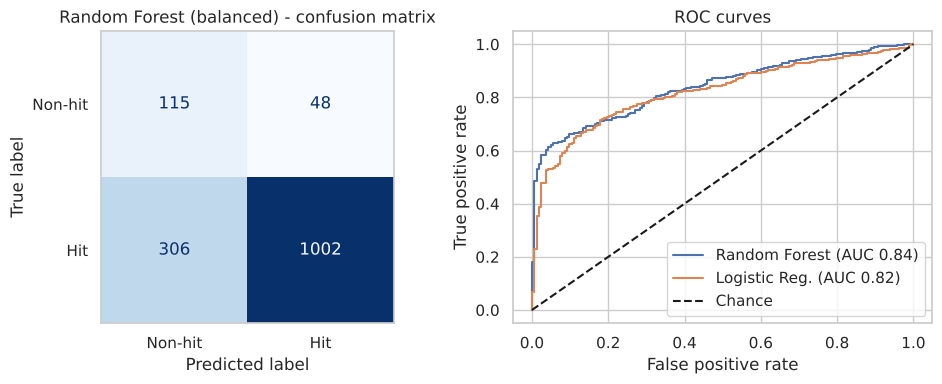

In [6]:
Xtr2, Xte2, ytr2, yte2 = train_test_split(Xd, yd, test_size=.2, random_state=RS, stratify=yd)
rf = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=RS, n_jobs=-1).fit(Xtr2, ytr2)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RS)).fit(Xtr2, ytr2)
pred = rf.predict(Xte2)
print(classification_report(yte2, pred, target_names=["Non-hit","Hit"]))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(yte2, pred, display_labels=["Non-hit","Hit"], cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Random Forest (balanced) - confusion matrix"); ax[0].grid(False)
for n, m in [("Random Forest", rf), ("Logistic Reg.", lr)]:
    f, t, _ = roc_curve(yte2, m.predict_proba(Xte2)[:,1]); ax[1].plot(f, t, label=f"{n} (AUC {roc_auc_score(yte2, m.predict_proba(Xte2)[:,1]):.2f})")
ax[1].plot([0,1],[0,1],"k--",label="Chance"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(); ax[1].set_title("ROC curves")
plt.tight_layout(); plt.savefig("figures/final_model.png", dpi=160); plt.show()

## 6. Which features matter?

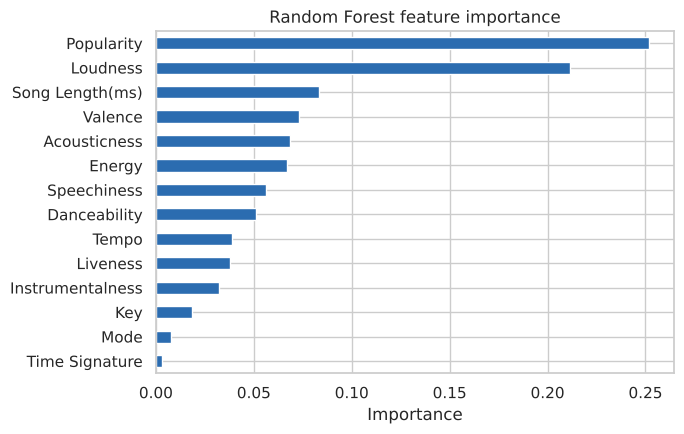

Popularity          0.252
Loudness            0.212
Song Length(ms)     0.083
Valence             0.073
Acousticness        0.069
Energy              0.067
Speechiness         0.056
Danceability        0.051
Tempo               0.039
Liveness            0.038
Instrumentalness    0.032
Key                 0.018
Mode                0.008
Time Signature      0.003
dtype: float64


In [7]:
imp = pd.Series(rf.feature_importances_, index=Xd.columns).sort_values()
plt.figure(figsize=(7, 4.5)); imp.plot(kind="barh", color="#2b6cb0"); plt.title("Random Forest feature importance"); plt.xlabel("Importance")
plt.tight_layout(); plt.savefig("figures/feature_importance.png", dpi=160); plt.show()
print(imp.sort_values(ascending=False).round(3))

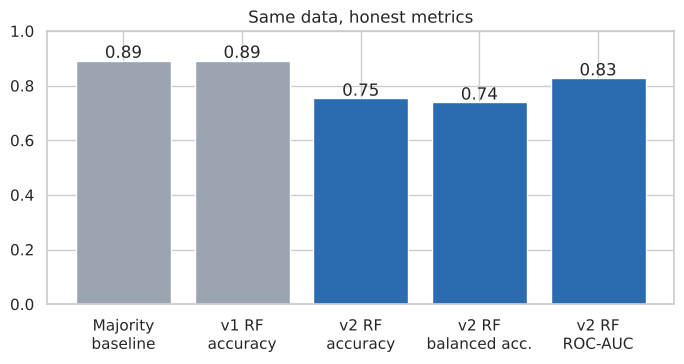

In [8]:
# Comparison chart: v1 reported accuracy vs. honest metrics
labels = ["Majority\nbaseline", "v1 RF\naccuracy", "v2 RF\naccuracy", "v2 RF\nbalanced acc.", "v2 RF\nROC-AUC"]
vals = [v1.loc["Majority baseline","Accuracy"], v1.loc["v1 Random Forest","Accuracy"], res_all.loc["Random Forest","_accuracy"],
        res_all.loc["Random Forest","_balanced_acc"], res_all.loc["Random Forest","_auc"]]
plt.figure(figsize=(7,3.8)); b = plt.bar(labels, vals, color=["#9aa5b1","#9aa5b1","#2b6cb0","#2b6cb0","#2b6cb0"])
for r, v in zip(b, vals): plt.text(r.get_x()+r.get_width()/2, v+.01, f"{v:.2f}", ha="center")
plt.ylim(0,1); plt.title("Same data, honest metrics"); plt.tight_layout(); plt.savefig("figures/metrics_compare.png", dpi=160); plt.show()

## 7. Live demo: predict a song
Train on all (de-duplicated) data, then score a feature vector. Probabilities use the balanced model, so 0.5 is a fair cut-off.

In [9]:
final_rf = RandomForestClassifier(n_estimators=300, max_depth=10, class_weight="balanced", random_state=RS, n_jobs=-1).fit(Xd, yd)

def predict_song(**f):
    row = pd.DataFrame([f])[FEATS]
    p = final_rf.predict_proba(row)[0, 1]
    return f"P(Billboard hit) = {p:.2f} -> {'HIT' if p >= .5 else 'NOT a hit'}"

print(predict_song(Popularity=80, Acousticness=.15, Danceability=.75, Energy=.80, Instrumentalness=0, Liveness=.1,
                   Loudness=-5.0, Speechiness=.06, Tempo=118, Valence=.6, Key=5, Mode=1, **{"Time Signature":4, "Song Length(ms)":200000}))
print(predict_song(Popularity=30, Acousticness=.80, Danceability=.35, Energy=.20, Instrumentalness=.1, Liveness=.15,
                   Loudness=-14.0, Speechiness=.04, Tempo=90, Valence=.25, Key=2, Mode=1, **{"Time Signature":4, "Song Length(ms)":230000}))

P(Billboard hit) = 0.30 -> NOT a hit
P(Billboard hit) = 0.98 -> HIT


## 8. Conclusions and limitations
* **v1's headline (89%) was the majority-class baseline.** With imbalance handled, the models reach ~0.74-0.75 balanced accuracy and ROC-AUC 0.79-0.83: real but modest signal (Stanford's balanced dataset reached ~75% accuracy).
* Random Forest ranks best on AUC; Logistic Regression and Decision Tree find more non-hits (higher recall) at lower precision. Precision for the non-hit class stays low (~0.24-0.27) because non-hits are only 11% of the data.
* Removing `Popularity` costs ~0.02-0.04 AUC, so the audio features alone still carry signal.
* **Limitations.** (1) Non-hits are playlist songs not matched *by title* to Billboard, so some are mislabelled and they are popular songs, not typical songs. (2) Hits span 1946-2022 while non-hits are ~2000+, so `Loudness`/`Energy` partly encode *era*. (3) `Popularity` is Spotify's *current* popularity, a partial leak of success. (4) Random splits ignore time; a temporal split would be the next test.
* **Future work.** Rebuild non-hits from a larger neutral catalogue (e.g. Million Song Dataset like the Stanford paper), match on title+artist, add an artist-history feature, evaluate with a time-based split.